# 01 · Dữ liệu, giao thức đánh giá và baseline heuristic

**Đồ án:** Ứng dụng mạng nơ-ron đồ thị động tích hợp thông tin thời gian trong hệ thống gợi ý địa điểm cá nhân hóa.

Bộ ba notebook này chạy lại toàn bộ phần so sánh mô hình, từng bước và có biểu đồ:

| Notebook | Nội dung |
|---|---|
| **01** (file này) | Dữ liệu Đà Nẵng, cách chia train/test, 3 baseline heuristic |
| 02 | 4 baseline machine learning cổ điển: User-KNN, Item-KNN, BPR-MF, Gradient Boosting |
| 03 | LightGCN, TAS-GNN và bảng so sánh chung 9 phương pháp |

Chạy theo thứ tự 01 → 02 → 03. Mỗi notebook lưu kết quả của mình vào `outputs/benchmark_ranks/`; notebook 03 gộp lại và ghi file cho trang `/evaluation` của website.

In [1]:
import sys, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Tìm thư mục gốc dự án (nơi có src/benchmark_ml.py) dù notebook được mở từ đâu.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "benchmark_ml.py").is_file())
sys.path[:0] = [str(ROOT), str(ROOT / "src")]
import benchmark_ml as bm

warnings.filterwarnings("ignore")
INK, SEA, CORAL, SAND, SKY, MUTED = "#1d2b2f", "#1f6f78", "#c8553d", "#b8860b", "#3d6a9e", "#9aa5a8"
GROUP_COLOR = {"heuristic": SAND, "ml": SKY, "gnn": SEA}
GROUP_NAME = {"heuristic": "Heuristic", "ml": "Machine learning cổ điển", "gnn": "Mạng nơ-ron đồ thị"}
CATEGORY_NAME = {"cafe": "Cà phê", "restaurant": "Ăn uống", "hotel": "Lưu trú", "tourist_spot": "Tham quan"}
CATEGORY_COLOR = {"cafe": SAND, "restaurant": CORAL, "hotel": SKY, "tourist_spot": SEA}
LABEL = {key: label for key, label, _ in bm.MODELS}
GROUP = {key: group for key, _, group in bm.MODELS}
plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (9, 4.2), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "axes.titleweight": "bold", "axes.titlesize": 12,
                     "axes.edgecolor": MUTED, "text.color": INK, "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK})

bench = bm.prepare()
print(f"{bench.n_users:,} người dùng · {bench.n_items:,} địa điểm · {len(bench.events):,} lượt check-in")
print(f"Train {len(bench.train):,} · Test {len(bench.test):,} · Test tại địa điểm mới (được chấm) {len(bench.novel):,}")


def color_of(key):
    return CORAL if key == "tas_gnn" else GROUP_COLOR[GROUP[key]]


def show_results(ranks, title, metric="HR@10"):
    """Bảng chỉ số (%) và biểu đồ cột của các phương pháp đã có kết quả."""
    table = bm.results_table(ranks)
    display(table.drop(columns=["model", "group"]).rename(columns={"label": "Phương pháp"}).set_index("Phương pháp")
            .style.format("{:.2f}").background_gradient(cmap="YlGn", axis=0))
    ordered = table.sort_values(metric)
    fig, ax = plt.subplots(figsize=(9, .5 * len(ordered) + 1.4))
    bars = ax.barh(ordered.label, ordered[metric], color=[color_of(k) for k in ordered.model])
    ax.bar_label(bars, fmt="%.2f%%", padding=4)
    ax.set(xlabel=f"{metric} (%)", title=title, xlim=(0, ordered[metric].max() * 1.18))
    ax.grid(axis="y", visible=False)
    plt.show()
    return table


1,500 người dùng · 996 địa điểm · 36,210 lượt check-in
Train 28,360 · Test 7,850 · Test tại địa điểm mới (được chấm) 6,811


## 1. Giao thức đánh giá

Mọi phương pháp dùng **chung một giao thức**, nên các con số so sánh được với nhau:

1. Check-in của mỗi người dùng được sắp theo thời gian; **80% đầu để huấn luyện, 20% cuối để kiểm tra**.
2. Chỉ chấm các sự kiện test tại **địa điểm người đó chưa từng ghé** trong train (gợi ý nơi mới, không phải đoán lại nơi quen).
3. Mô hình xếp hạng **toàn bộ danh mục** trừ các nơi đã ghé; không lấy mẫu ứng viên.
4. Chấm **tất cả** sự kiện, với giờ và thứ thật của từng sự kiện.

Chỉ số: **HR@K** (địa điểm đúng có nằm trong top K không), **NDCG@K** và **MRR@K** (nằm càng cao càng được điểm).

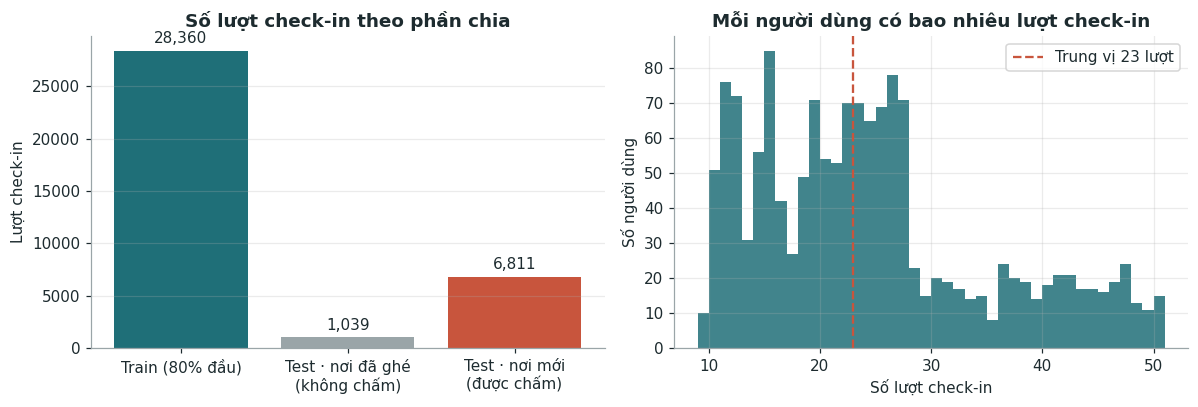

In [2]:
per_user = bench.events.groupby("u").size()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
parts = [len(bench.train), len(bench.test) - len(bench.novel), len(bench.novel)]
names = ["Train (80% đầu)", "Test · nơi đã ghé\n(không chấm)", "Test · nơi mới\n(được chấm)"]
bars = axes[0].bar(names, parts, color=[SEA, MUTED, CORAL])
axes[0].bar_label(bars, labels=[f"{v:,}" for v in parts], padding=3)
axes[0].set(title="Số lượt check-in theo phần chia", ylabel="Lượt check-in")
axes[0].grid(axis="x", visible=False)
axes[1].hist(per_user, bins=range(per_user.min(), per_user.max() + 2), color=SEA, alpha=.85)
axes[1].axvline(per_user.median(), color=CORAL, ls="--", label=f"Trung vị {per_user.median():.0f} lượt")
axes[1].set(title="Mỗi người dùng có bao nhiêu lượt check-in", xlabel="Số lượt check-in", ylabel="Số người dùng")
axes[1].legend()
plt.tight_layout(); plt.show()

## 2. Nhìn dữ liệu trước khi chọn baseline

Ba câu hỏi quyết định baseline nào đáng thử: người ta đi đâu **vào giờ nào**, lượt ghé có **dồn vào ít địa điểm** không, và hai lần ghé liên tiếp **cách nhau bao xa**.

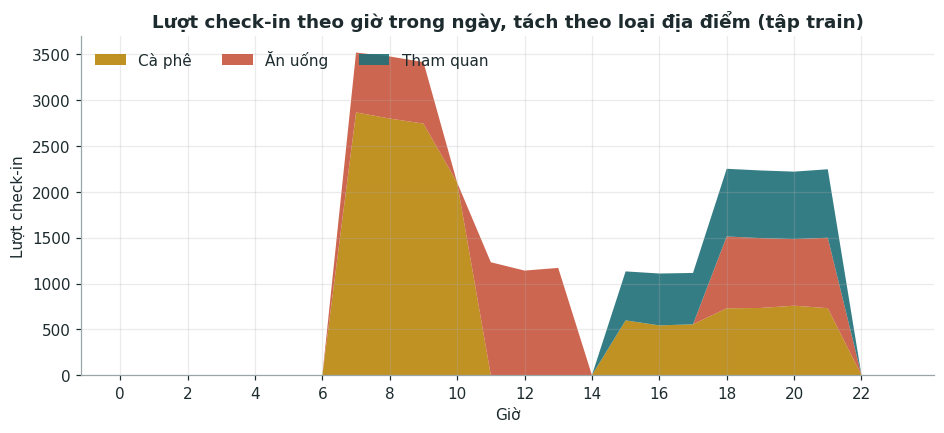

Loại địa điểm đông nhất theo giờ: 7h→Cà phê, 9h→Cà phê, 12h→Ăn uống, 15h→Cà phê, 19h→Ăn uống, 21h→Ăn uống


In [3]:
train = bench.train.merge(bench.pois[["l", "category"]], on="l")
by_hour = train.pivot_table(index="hour", columns="category", values="u", aggfunc="size", fill_value=0).reindex(range(24), fill_value=0)
by_hour = by_hour[[c for c in CATEGORY_NAME if c in by_hour.columns]]
fig, ax = plt.subplots(figsize=(10, 4))
ax.stackplot(by_hour.index, by_hour.T.values, labels=[CATEGORY_NAME[c] for c in by_hour.columns],
             colors=[CATEGORY_COLOR[c] for c in by_hour.columns], alpha=.9)
ax.set(title="Lượt check-in theo giờ trong ngày, tách theo loại địa điểm (tập train)", xlabel="Giờ", ylabel="Lượt check-in", xticks=range(0, 24, 2))
ax.legend(loc="upper left", ncol=4, frameon=False)
plt.show()
share = (by_hour.T / by_hour.sum(1)).T.fillna(0)
print("Loại địa điểm đông nhất theo giờ:", ", ".join(f"{h}h→{CATEGORY_NAME[share.loc[h].idxmax()]}" for h in (7, 9, 12, 15, 19, 21) if by_hour.loc[h].sum()))

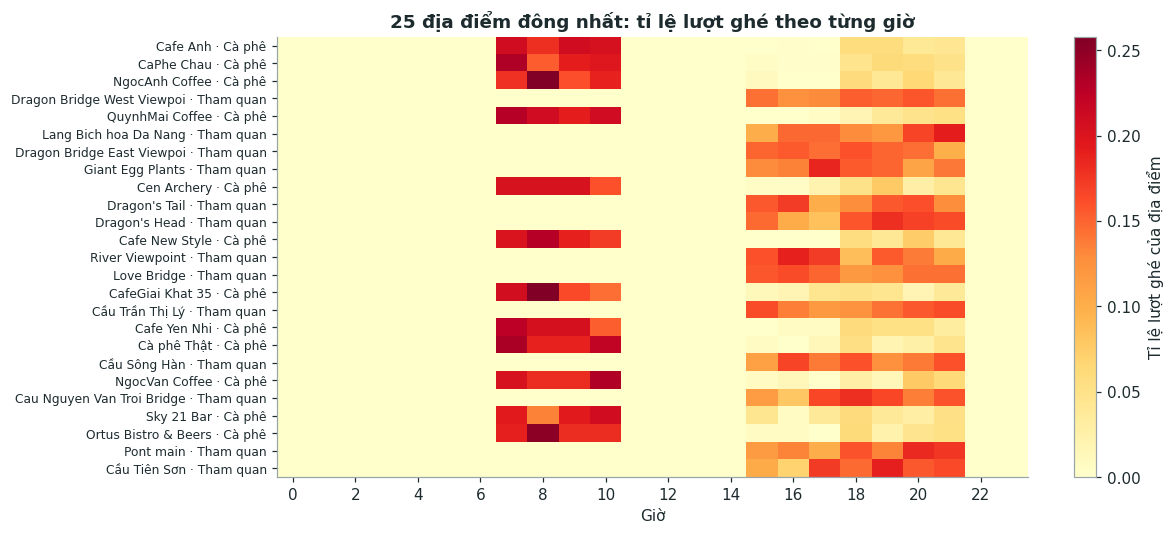

In [4]:
top = np.argsort(-bench.popularity)[:25]
heat = bench.hourly[:, top] / np.maximum(bench.hourly[:, top].sum(0), 1)
fig, ax = plt.subplots(figsize=(11, 5.2))
image = ax.imshow(heat.T, aspect="auto", cmap="YlOrRd")
ax.set(title="25 địa điểm đông nhất: tỉ lệ lượt ghé theo từng giờ", xlabel="Giờ", xticks=range(0, 24, 2), yticks=range(len(top)))
ax.set_yticklabels([f"{bench.pois.name[i][:26]} · {CATEGORY_NAME[bench.pois.category[i]]}" for i in top], fontsize=8)
ax.grid(False)
fig.colorbar(image, ax=ax, label="Tỉ lệ lượt ghé của địa điểm")
plt.show()

Mỗi địa điểm có khung giờ riêng của nó. Đây là lý do baseline **phổ biến theo giờ** được đưa vào, và cũng là tín hiệu mà TAS-GNN phải học được.

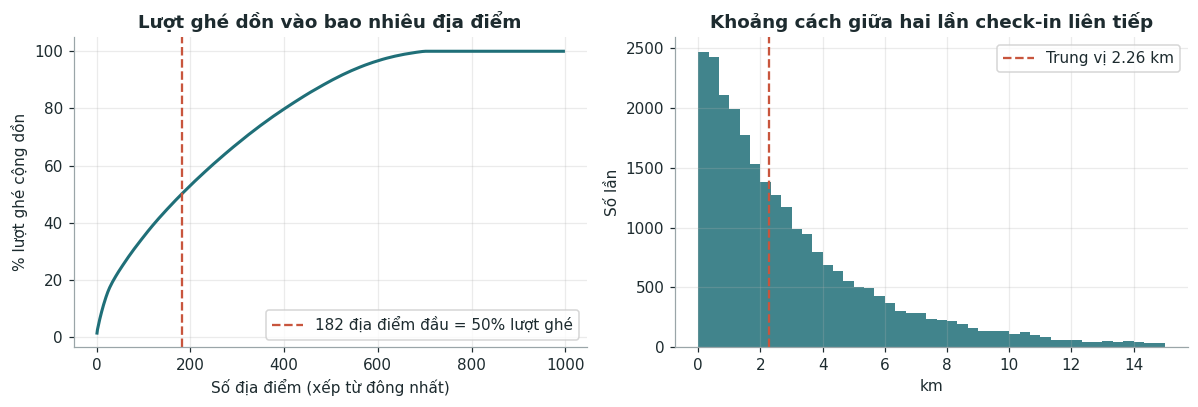

295 địa điểm không có lượt ghé nào trong train (chủ yếu là nơi lưu trú).
26% lần di chuyển dưới 1 km, 60% dưới 3 km.


In [5]:
from baselines.feature_gbm import km

order = np.sort(bench.popularity)[::-1]
cumulative = np.cumsum(order) / order.sum()
ev = bench.train.sort_values(["u", "ts"])
prev = ev.groupby("u").l.shift(1)
ok = prev.notna()
a, b = bench.coords[prev[ok].astype(int)], bench.coords[ev.l[ok]]
step_km = km(a[:, 0], a[:, 1], b[:, 0], b[:, 1])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(np.arange(1, len(order) + 1), cumulative * 100, color=SEA, lw=2)
half = int(np.searchsorted(cumulative, .5)) + 1
axes[0].axvline(half, color=CORAL, ls="--", label=f"{half} địa điểm đầu = 50% lượt ghé")
axes[0].set(title="Lượt ghé dồn vào bao nhiêu địa điểm", xlabel="Số địa điểm (xếp từ đông nhất)", ylabel="% lượt ghé cộng dồn")
axes[0].legend()
axes[1].hist(step_km, bins=np.linspace(0, 15, 46), color=SEA, alpha=.85)
axes[1].axvline(np.median(step_km), color=CORAL, ls="--", label=f"Trung vị {np.median(step_km):.2f} km")
axes[1].set(title="Khoảng cách giữa hai lần check-in liên tiếp", xlabel="km", ylabel="Số lần")
axes[1].legend()
plt.tight_layout(); plt.show()
print(f"{(bench.popularity == 0).sum()} địa điểm không có lượt ghé nào trong train (chủ yếu là nơi lưu trú).")
print(f"{(step_km <= 1).mean():.0%} lần di chuyển dưới 1 km, {(step_km <= 3).mean():.0%} dưới 3 km.")

## 3. Ba baseline heuristic

Không có tham số nào phải học, chỉ đếm trên tập train:

| Baseline | Điểm của địa điểm *j* | Thông tin dùng |
|---|---|---|
| **Phổ biến chung** | số lượt ghé *j* | không cá nhân hóa, không thời gian |
| **Phổ biến theo giờ** | số lượt ghé *j* vào đúng giờ đang xét | thời gian |
| **Giờ × khoảng cách liền trước** | (lượt ghé *j* vào giờ đó) / (khoảng cách từ nơi vừa ghé + 0,5 km) | thời gian + **vị trí ngay trước đó** |

Lưu ý: baseline thứ ba được biết người dùng **vừa ở đâu**. Các mô hình còn lại (kể cả TAS-GNN) không dùng thông tin này, nên nó là một mốc tham chiếu mạnh chứ không phải so sánh ngang hàng.

Phổ biến chung                   chấm 6,811 sự kiện trong 0.0 s
Phổ biến theo giờ                chấm 6,811 sự kiện trong 0.1 s


Giờ × khoảng cách liền trước     chấm 6,811 sự kiện trong 0.3 s


,HR@5,NDCG@5,MRR@5,HR@10,NDCG@10,MRR@10,HR@20,NDCG@20,MRR@20
Phương pháp,,,,,,,,,
Phổ biến chung,2.17,1.01,0.65,6.12,2.29,1.17,11.19,3.56,1.51
Phổ biến theo giờ,6.33,3.78,2.95,10.53,5.13,3.50,16.37,6.61,3.91
Giờ × khoảng cách liền trước,9.90,6.54,5.44,14.64,8.05,6.05,21.79,9.85,6.54


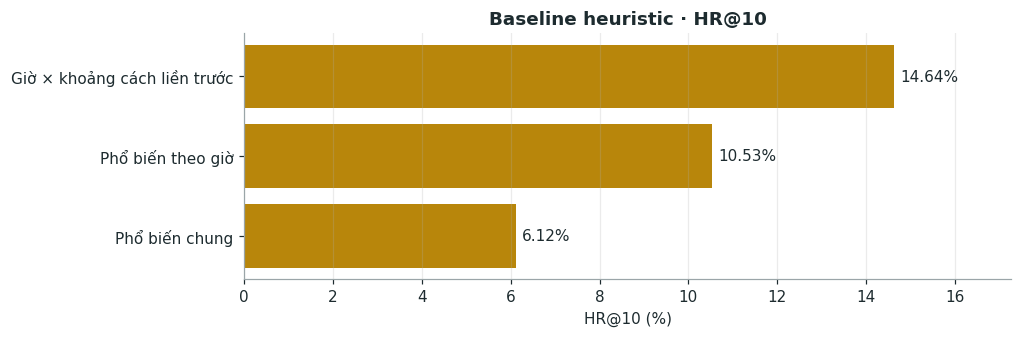

In [6]:
ranks = {}
for key, scorer in bm.heuristic_scorers(bench).items():
    start = time.perf_counter()
    ranks[key] = bm.evaluate(bench, scorer)
    bm.save_ranks(key, ranks[key], 0.0)
    print(f"{LABEL[key]:<32} chấm {len(ranks[key]):,} sự kiện trong {time.perf_counter() - start:.1f} s")
table = show_results(ranks, "Baseline heuristic · HR@10")

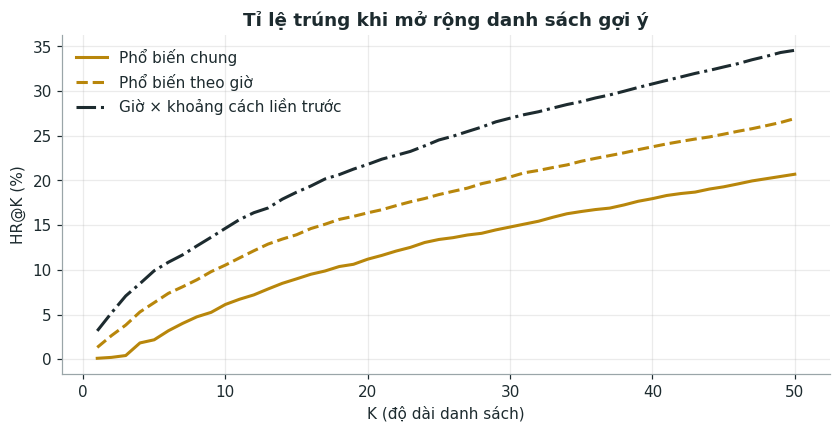

Thêm thông tin giờ: 6.12% → 10.53% (×1.72).
Thêm vị trí liền trước: → 14.64%.


In [7]:
ks = np.arange(1, 51)
fig, ax = plt.subplots(figsize=(9, 4))
for key, style in zip(ranks, ("-", "--", "-.")):
    ax.plot(ks, [(ranks[key] <= k).mean() * 100 for k in ks], style, lw=2, label=LABEL[key], color=INK if key == "hour_prev_distance" else SAND)
ax.set(title="Tỉ lệ trúng khi mở rộng danh sách gợi ý", xlabel="K (độ dài danh sách)", ylabel="HR@K (%)")
ax.legend(frameon=False)
plt.show()
gain = table.set_index("model")["HR@10"]
print(f"Thêm thông tin giờ: {gain['popularity']:.2f}% → {gain['hourly_popularity']:.2f}% (×{gain['hourly_popularity'] / gain['popularity']:.2f}).")
print(f"Thêm vị trí liền trước: → {gain['hour_prev_distance']:.2f}%.")

## Nhận xét

- Chỉ cần biết **giờ** đã cải thiện rõ so với phổ biến chung: thời gian là tín hiệu thật trong dữ liệu này.
- Biết thêm **vị trí liền trước** cải thiện tiếp một bậc, vì phần lớn lần di chuyển rất ngắn.
- Cả ba đều **không cá nhân hóa**: hai người khác nhau, cùng giờ và cùng chỗ đứng, nhận cùng một danh sách.

Tiếp theo: `02_baseline_machine_learning.ipynb`.